<a href="https://colab.research.google.com/github/MightyNine/The-Mighty-Nein/blob/main/LSTM_Model_for_Aposemat2023_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**1. Imports and Setup**

In [ ]:
# Standard-library helpers
import os          # file-path checks and file-size lookups
import gc          # manual garbage collection to free RAM after heavy steps
import re          # regular expressions used to tidy up column names
import json        # saves the final threshold/config as a small JSON file
import time        # measures inference speed in the efficiency profile
import warnings    # lets us silence harmless warnings so the output stays readable

# Core data handling libraries
import pandas as pd   # for loading and manipulating the CSV data
import numpy as np    # for numerical array operations (windows, maths)

# Preprocessing tools from scikit-learn
from sklearn.preprocessing import StandardScaler   # scales features to mean=0, std=1
from sklearn.ensemble import IsolationForest       # classical baseline model used for comparison (Cell 19)

# Evaluation metrics
from sklearn.metrics import (  # import the evaluation metrics listed below
    confusion_matrix,          # builds the confusion matrix (TP/FP/TN/FN)
    classification_report,     # gives precision/recall/f1 per class
    roc_auc_score,             # area under ROC curve (overall separability)
    roc_curve,                 # points to plot the ROC curve
    precision_recall_curve,    # points to plot the precision/recall trade-off
    average_precision_score,   # area under the precision-recall curve (PR-AUC)
    matthews_corrcoef,         # single balanced score that is robust to class imbalance
    balanced_accuracy_score,   # average of recall on normal and recall on anomaly
    precision_score,           # precision at a given threshold
    recall_score,              # recall at a given threshold
    f1_score                   # F1 at a given threshold
)

# Statistics helper used to test whether two error distributions differ
from scipy.stats import ks_2samp   # two-sample Kolmogorov-Smirnov test

# Saving/loading fitted objects such as the scaler
import joblib   # serialises the fitted StandardScaler to disk

# Deep learning framework
import tensorflow as tf                                                                  # main TensorFlow library
from tensorflow.keras.models import Model                                                # for building the custom autoencoder architecture
from tensorflow.keras.layers import Input, LSTM, RepeatVector, TimeDistributed, Dense    # LSTM autoencoder building blocks
from tensorflow.keras.optimizers import Adam                                             # optimizer (lets us set learning rate and gradient clipping)
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau # training callbacks

# Plotting libraries
import matplotlib.pyplot as plt                 # static plots (loss curves, histograms, ROC curves)
import seaborn as sns                           # nicer heatmaps for the confusion matrix and explainability
import matplotlib.animation as animation        # for the live-streaming demo panel later
from IPython.display import HTML                # to render the animation inline in Colab

warnings.filterwarnings('ignore')               # hide harmless library warnings to keep output clean

# Set a random seed everywhere so results are reproducible across reruns
SEED = 42                       # the single seed used throughout the notebook
np.random.seed(SEED)            # seed numpy's random generator
tf.random.set_seed(SEED)        # seed TensorFlow's random generator

# ------------------------- CONFIGURATION (edit here only) -------------------------
DATA_PATH        = '/content/Aposemat IoT23 Dataset.csv'  # dataset uploaded to Colab session storage (not Drive)
BLOCK_SIZE       = 20000       # rows per contiguous "block"; whole blocks are assigned to train/val/test
MAX_ROWS         = 3_000_000    # cap on rows loaded (set to None to load everything if RAM allows)
WINDOW_SIZE      = 10           # number of consecutive flow records per sequence (same as CICIoT2023 notebook)
STEP_SIZE        = 1            # how far the window slides each time (1 = maximum overlap)
TEST_BLOCK_FRAC  = 0.30         # fraction of blocks held out as the TEST set
VAL_BLOCK_FRAC   = 0.15         # fraction of blocks held out as the VALIDATION set (used to set the threshold)
MAX_TRAIN_SEQ    = 300_000      # cap on benign training sequences (keeps Colab RAM/time under control)
MAX_VAL_SEQ      = 100_000      # cap on benign validation sequences
MAX_TEST_SEQ     = 300_000      # cap on test sequences (thinned evenly so time order is preserved)
SCALE_CLIP       = 20.0         # scaled values are clipped to +/- this to stop single extreme flows dominating the error
PORTSCAN_AS_BOTNET = False      # False = horizontal port scans are treated as out-of-scope ('Other') like Recon in CICIoT2023

print("All libraries imported successfully.")                                     # confirmation message
print(f"TensorFlow version: {tf.__version__}")                                    # show the TensorFlow version in use
print(f"GPU available: {len(tf.config.list_physical_devices('GPU')) > 0}")       # training is much faster on a GPU runtime


All libraries imported successfully.
TensorFlow version: 2.20.0
GPU available: True


**Google Cloud Import for Dataset**

In [ ]:
from google.colab import drive                                                     # Colab helper to mount Google Drive
import os                                                                          # file-size lookups
import shutil                                                                      # file copying

drive.mount('/content/drive')                                                      # mount your Drive (click through the permission pop-up)
SRC = '/content/drive/MyDrive/Aposemat IoT23 Dataset.csv'                         # the full file you uploaded to Drive (edit if you put it in a folder)
DST = '/content/Aposemat IoT23 Dataset.csv'                                        # the path Cell 1 reads (this replaces whatever's there)

assert os.path.exists(SRC), f"Not found: {SRC} — check the file name and folder in Drive."   # stop with a clear message if the path is wrong
print(f"Source size: {os.path.getsize(SRC) / (1024 ** 3):.3f} GB (should be about 0.84)")   # confirm Drive has the full file
shutil.copyfile(SRC, DST)                                                          # copy it into Colab session storage
print(f"Copied file size: {os.path.getsize(DST) / (1024 ** 3):.3f} GB")            # confirm the copy is complete

Mounted at /content/drive
Source size: 0.841 GB (should be about 0.84)
Copied file size: 0.841 GB


**2. Loading the Dataset**

In [ ]:
# 2A. Peek at the header to learn the delimiter and the column names
assert os.path.exists(DATA_PATH), f"File not found at {DATA_PATH} — upload it via the Colab Files panel and check the file name."  # stop early with a clear message
print(f"File size: {os.path.getsize(DATA_PATH) / (1024 ** 3):.2f} GB")                    # report the size so we know what we are handling

with open(DATA_PATH, 'r', encoding='utf-8', errors='replace') as f:                          # open the file as text
    header_line = f.readline()                                                               # read only the first line (the header)
SEP = ',' if header_line.count(',') >= header_line.count('\t') else '\t'                    # use a comma unless tabs dominate the header
raw_columns = list(pd.read_csv(DATA_PATH, sep=SEP, nrows=0).columns)                        # read zero rows just to obtain the column names

def norm(name):  # helper that standardises column names
    """Normalises a column name: lowercase, with every run of symbols replaced by a single underscore."""
    return re.sub(r'[^0-9a-z]+', '_', str(name).strip().lower()).strip('_')                # e.g. 'detailed-label' -> 'detailed_label', 'id.resp_p' -> 'id_resp_p'

col_map = {norm(c): c for c in raw_columns}   # normalised name -> original name in the file

# The Zeek conn.log fields we know how to use (see the IoT-23 documentation)
NUMERIC_RAW     = ['duration', 'orig_bytes', 'resp_bytes', 'missed_bytes',  # numeric flow statistics (list continues below)
                   'orig_pkts', 'orig_ip_bytes', 'resp_pkts', 'resp_ip_bytes']   # numeric flow statistics
CATEGORICAL_RAW = ['proto', 'service', 'conn_state']                             # categorical flow descriptors
PORT_COL        = 'id_resp_p'                                                    # destination (responder) port
TIME_COL        = 'ts'                                                           # flow start timestamp
COMBINED_COL    = 'tunnel_parents_label_detailed_label'                          # raw Zeek files sometimes merge these 3 fields into one column
LABEL_NAMES     = ['label', 'detailed_label', COMBINED_COL]                      # every label-related column we might need

present_numeric = [c for c in NUMERIC_RAW if c in col_map]                       # which of the numeric fields exist in this file
GENERIC_MODE = len(present_numeric) < 4                                          # fall back to a generic numeric pipeline if the file is not conn.log-style
print(f"Columns found ({len(raw_columns)}): {raw_columns}")                      # show what the file contains
print(f"Pipeline mode: {'GENERIC numeric fallback' if GENERIC_MODE else 'Zeek conn.log feature engineering'}")   # tell the team which path is used

if GENERIC_MODE:  # generic fallback path
    usecols = None                                                               # load every column in generic mode
else:  # otherwise
    wanted = (present_numeric + [c for c in CATEGORICAL_RAW if c in col_map]  # numeric + categorical columns that exist (continues below)
              + [c for c in [PORT_COL, TIME_COL] + LABEL_NAMES if c in col_map]) # only the columns we will actually use (saves RAM)
    usecols = [col_map[c] for c in wanted]                                       # translate back to the original column names

# 2B. Count rows and decide which blocks to keep
def count_lines(path):  # helper that counts rows without loading the file
    """Counts newline characters quickly by reading the file in 16 MB binary pieces."""
    n = 0                                                    # running line counter
    with open(path, 'rb') as fh:                             # open in binary mode (fastest)
        for piece in iter(lambda: fh.read(1 << 24), b''):    # read 16 MB at a time until the end of the file
            n += piece.count(b'\n')                          # count line breaks in this piece
    return n                                                 # total number of newline characters

total_rows = max(count_lines(DATA_PATH) - 1, 1)              # subtract the header line
n_blocks_total = int(np.ceil(total_rows / BLOCK_SIZE))       # number of blocks the file splits into
rng = np.random.default_rng(SEED)                            # reproducible random generator for block sampling

if MAX_ROWS is None or total_rows <= MAX_ROWS:  # no row cap needed
    keep_blocks = set(range(n_blocks_total))                                                        # keep every block
else:  # otherwise
    n_keep = max(1, MAX_ROWS // BLOCK_SIZE)                                                         # how many blocks fit in the row cap
    keep_blocks = set(rng.choice(n_blocks_total, size=n_keep, replace=False).tolist())              # random whole blocks (keeps flows contiguous for the LSTM)
print(f"Total rows in file: {total_rows:,} | blocks: {n_blocks_total} | keeping {len(keep_blocks)} blocks")   # summary of the sampling decision

# 2C. Read the file block by block and store compact numeric data
chunks = []                                                  # will hold one DataFrame per kept block
reader = pd.read_csv(DATA_PATH, sep=SEP, usecols=usecols, chunksize=BLOCK_SIZE,  # lazy reader that yields one BLOCK_SIZE block at a time
                     na_values=['-', '(empty)'], low_memory=False)   # Zeek writes '-' / '(empty)' for "unset", so treat them as missing
for block_id, chunk in enumerate(reader):                    # loop over the file in BLOCK_SIZE-row pieces
    if block_id not in keep_blocks:                          # skip blocks that were not sampled
        continue  # skip to the next item
    chunk.columns = [norm(c) for c in chunk.columns]         # give every column its normalised name
    chunk['block_id'] = np.int32(block_id)                   # remember which block each row came from
    for c in chunk.columns:                                  # shrink numeric columns to save memory
        if pd.api.types.is_float_dtype(chunk[c]) and c != TIME_COL:   # only touch floating-point columns (keep 'ts' in float64 to preserve precision)
            chunk[c] = chunk[c].astype('float32')            # float32 uses half the memory of float64
    chunks.append(chunk)                                     # store this block

df = pd.concat(chunks, ignore_index=True)                    # join all kept blocks into one DataFrame (file order preserved)
del chunks                                                   # free the list of pieces
gc.collect()                                                 # release memory back to the system

# Some raw Zeek exports merge three fields into one column — split them back apart
if 'label' not in df.columns and COMBINED_COL in df.columns:  # only when the label fields are merged in one column
    parts = df[COMBINED_COL].fillna('').astype(str).str.strip().str.split(r'\s+', n=2, expand=True, regex=True)   # split on runs of whitespace
    if parts.shape[1] >= 2:                                  # need at least tunnel_parents + label
        df['label'] = parts[1]                               # second piece is the Benign/Malicious label
    if parts.shape[1] >= 3:                                  # third piece is the detailed label
        df['detailed_label'] = parts[2]                      # e.g. PartOfAHorizontalPortScan, Okiru, DDoS, C&C ...
    df = df.drop(columns=[COMBINED_COL])                     # the merged column is no longer needed

# 2D. Ensure that flows are in time order (the LSTM relies on sequence order)
if TIME_COL in df.columns and not GENERIC_MODE:  # only when a timestamp column exists
    ts_values = pd.to_numeric(df[TIME_COL], errors='coerce').to_numpy()                 # timestamps as numbers
    ordered_fraction = float(np.mean(np.diff(ts_values) >= 0)) if len(ts_values) > 1 else 1.0   # share of consecutive flows already in time order
    print(f"Share of consecutive rows already in time order: {ordered_fraction:.4f}")     # diagnostic for the team
    if ordered_fraction < 0.99:                                                          # file looks shuffled
        df = df.sort_values(TIME_COL, kind='stable').reset_index(drop=True)              # restore chronological order
        df['block_id'] = (np.arange(len(df)) // BLOCK_SIZE).astype(np.int32)             # re-cut contiguous blocks after sorting
        print("File was not time-ordered — sorted by timestamp and re-blocked.")         # tell the team what happened

print(f"\nLoaded shape: {df.shape}")                                                     # rows x columns actually in memory
print(f"Approx. memory: {df.memory_usage(deep=True).sum() / (1024 ** 3):.2f} GB")        # how much RAM the DataFrame uses

# Displays how many rows exist for each label value (distribution before mapping)
for lab in ['label', 'detailed_label']:                      # look at both label columns if present
    if lab in df.columns:                                    # skip a column that does not exist
        print(f"\nDistribution of '{lab}':")                # header for this distribution
        print(df[lab].fillna('<missing>').value_counts())    # counts per value, including missing values

File size: 0.84 GB
Columns found (22): ['Unnamed: 0', 'ts', 'uid', 'id.orig_h', 'id.orig_p', 'id.resp_h', 'id.resp_p', 'proto', 'service', 'duration', 'orig_bytes', 'resp_bytes', 'conn_state', 'local_orig', 'local_resp', 'missed_bytes', 'history', 'orig_pkts', 'orig_ip_bytes', 'resp_pkts', 'resp_ip_bytes', 'label']
Pipeline mode: Zeek conn.log feature engineering
Total rows in file: 6,046,623 | blocks: 303 | keeping 150 blocks
Share of consecutive rows already in time order: 0.9730
File was not time-ordered — sorted by timestamp and re-blocked.

Loaded shape: (2986623, 15)
Approx. memory: 0.71 GB

Distribution of 'label':
label
PartOfAHorizontalPortScan    1743858
Okiru                         559233
Benign                        372214
DDoS                          301264
C&C                             9130
C&C-HeartBeat                    533
Attack                           347
C&C-Torii                         30
C&C-FileDownload                  10
Okiru-Attack                   

**3. Map Granular Labels to the 4 Target Categories in The Dataset**

In [ ]:
# IoT-23 labels every flow as Benign/Malicious and adds a "detailed label" naming the behaviour (e.g. DDoS, Okiru, C&C, PartOfAHorizontalPortScan, Attack). We map these into the project's categories:
#   DDoS    <- 'DDoS'
#   Botnet      <- Okiru / Mirai / Torii / C&C / HeartBeat / FileDownload (botnet infection & command-and-control traffic)
#   BruteForce  <- 'Attack' (IoT-23 documents this as an infected device attacking another host, e.g. brute-forcing logins)
#   Other       <- horizontal port scans (reconnaissance, out of scope, mirroring Recon in the CICIoT2023 notebook)
#   DoS         <- IoT-23 has NO dedicated DoS label, so this category will simply be absent for this dataset
BENIGN_TOKENS = {'benign', 'normal', '0'}                                     # values that mean "normal traffic"
BOTNET_KEYS   = ['c&c', 'okiru', 'mirai', 'torii', 'heartbeat', 'filedownload']  # keywords identifying botnet behaviour

def map_to_category(binary_label, detailed_label):  # maps one flow's labels to a project category
    """
    Takes the binary label and the detailed label of one flow and returns one of:
    'Benign', 'DDoS', 'Botnet', 'BruteForce' or 'Other' (anything outside our project scope).
    """
    b = str(binary_label).strip().lower()      # normalise the Benign/Malicious label
    d = str(detailed_label).strip().lower()    # normalise the detailed label
    if b in BENIGN_TOKENS or (b in ('', 'nan', '-') and d in ('', 'nan', '-', 'benign', 'normal')):   # normal traffic
        return 'Benign'  # normal traffic
    if 'ddos' in d:                                                     # any distributed denial-of-service flow
        return 'DDoS'  # distributed denial-of-service
    if d == 'attack':                                                   # a pure "Attack" flow (login brute force, exploitation attempts)
        return 'BruteForce'  # brute-force / exploitation category
    if any(k in d for k in BOTNET_KEYS):                                # botnet families and command-and-control behaviour
        return 'Botnet'  # botnet category
    if 'portscan' in d:                                                 # horizontal port scan (reconnaissance)
        return 'Botnet' if PORTSCAN_AS_BOTNET else 'Other'              # controlled by the switch in Cell 1
    if 'attack' in d:                                                   # remaining combined labels that contain "attack"
        return 'BruteForce'  # brute-force / exploitation category
    return 'Other'                                                      # anything else is outside our defined project scope

label_series  = df['label'] if 'label' in df.columns else df['detailed_label']            # binary label (fallback: detailed label)
detail_series = df['detailed_label'] if 'detailed_label' in df.columns else label_series  # detailed label (fallback: binary label)
label_clean   = label_series.fillna('-').astype(str)                                      # replace missing values with '-'
detail_clean  = detail_series.fillna('-').astype(str).str.strip()                         # same for the detailed label

pair_key = label_clean + '||' + detail_clean                       # one string key per (label, detailed label) combination
key_to_category = {}                                               # lookup table: key -> mapped category
for key in pair_key.unique():                                      # only a handful of unique combinations exist
    b_val, d_val = key.split('||', 1)                              # split the key back into its two parts
    key_to_category[key] = map_to_category(b_val, d_val)           # map each unique combination once (fast)

df['category'] = pair_key.map(key_to_category)                     # vectorised lookup for every row
df['detail']   = detail_clean                                      # keep the detailed label for the per-behaviour breakdown later
df.loc[df['category'] == 'Benign', 'detail'] = 'Benign'            # tidy the display name of benign flows

# Show exactly how every raw label combination was mapped, so teammates can audit the mapping
mapping_table = (pd.DataFrame({'label': label_clean, 'detailed_label': detail_clean, 'category': df['category']})  # table of (label, detailed label, category) combinations (continues below)
                 .value_counts().rename('rows').reset_index())     # count rows per (label, detailed label, category)
print("Label mapping audit table:")                                # heading
print(mapping_table.to_string(index=False))                        # print the full table

print("\nMapped category distribution (before dropping 'Other'):")  # sanity check
print(df['category'].value_counts())                                # counts per mapped category

# Drop rows labelled 'Other' since they fall outside the defined project scope
before = len(df)                                                    # row count before dropping
df = df[df['category'] != 'Other'].reset_index(drop=True)           # keep only in-scope rows
print(f"\nDropped {before - len(df):,} out-of-scope rows.")         # how many rows were removed
print("Final in-scope category distribution:")                      # heading
print(df['category'].value_counts())                                # what the model will actually see

assert (df['category'] == 'Benign').any() and (df['category'] != 'Benign').any(), "After mapping there is no benign traffic or no attack traffic left — check the mapping audit table above and adjust map_to_category()."   # fail loudly if the label values were not recognised

if 'DoS' not in set(df['category']):                                # explain the missing category instead of failing silently
    print("\nNOTE: no 'DoS' rows exist in IoT-23 (it only labels DDoS, botnet, scan and attack behaviour) — this is expected.")  # print the message/results

Label mapping audit table:
                    label            detailed_label   category    rows
PartOfAHorizontalPortScan PartOfAHorizontalPortScan      Other 1743858
                    Okiru                     Okiru     Botnet  559233
                   Benign                    Benign     Benign  372214
                     DDoS                      DDoS       DDoS  301264
                      C&C                       C&C     Botnet    9130
            C&C-HeartBeat             C&C-HeartBeat     Botnet     533
                   Attack                    Attack BruteForce     347
                C&C-Torii                 C&C-Torii     Botnet      30
         C&C-FileDownload          C&C-FileDownload     Botnet      10
             Okiru-Attack              Okiru-Attack     Botnet       2
                C&C-Mirai                 C&C-Mirai     Botnet       1
             FileDownload              FileDownload     Botnet       1

Mapped category distribution (before dropping 'Ot

**4. Clean and Engineer Numeric Features**

In [ ]:
# Zeek conn.log fields combine text categories (protocol, service, status) with heavily-tailed numbers (bytes, packets, duration).
# LSTMs need purely numeric input; 1. log-transform the counts 2. add a few ratio features, 3. one-hot encode the categories, since LSTMs require just the numerical input

FIXED_PROTO   = ['tcp', 'udp', 'icmp']                                                                  # protocols we encode explicitly
FIXED_SERVICE = ['dns', 'http', 'ssl', 'dhcp', 'irc', 'ssh', 'ntp']                                     # services we encode explicitly (others -> 'other')
FIXED_STATE   = ['S0', 'S1', 'S2', 'S3', 'SF', 'REJ', 'RSTO', 'RSTR', 'RSTOS0', 'RSTRH', 'SH', 'SHR', 'OTH']   # every standard Zeek connection state

feat = {}   # will hold {feature name: 1-D float32 array}

def col_arr(name):  # helper that returns a cleaned float32 column
    """Returns a column as a clean float32 array: missing/inf values become 0 and negatives are clipped to 0."""
    arr = df[name].to_numpy(dtype=np.float32, na_value=np.nan)                        # column as a float32 array (missing -> NaN)
    arr = np.nan_to_num(arr, nan=0.0, posinf=0.0, neginf=0.0)                         # Zeek uses '-' for unset counters, i.e. zero activity
    return np.clip(arr, 0, None)                                                      # byte/packet counts can never be negative

if GENERIC_MODE:  # generic fallback path
    # ---- Generic fallback: use every numeric column except identifiers, labels and helper columns ----
    skip = {'block_id', 'ts', 'category', 'detail'} | {c for c in df.columns if c.startswith('unnamed')}   # columns that are not model inputs
    for c in df.columns:                                                              # loop over every column
        if c not in skip and c not in LABEL_NAMES and pd.api.types.is_numeric_dtype(df[c]):   # numeric feature columns only
            feat[c] = df[c].to_numpy(dtype=np.float32, na_value=np.nan)               # keep raw values (inf/NaN handled below)
else:  # otherwise
    # ---- Numeric flow statistics: log1p compresses the heavy right tail ----
    for c in present_numeric:                                                         # every numeric conn.log field found in the file
        feat[f'log_{c}'] = np.log1p(col_arr(c))                                       # log(1 + x) keeps zeros at zero

    # ---- Ratio features: how one-sided and how "chatty" a flow is ----
    if 'orig_bytes' in df.columns and 'resp_bytes' in df.columns:                     # need both directions
        feat['log_bytes_ratio'] = np.log1p(col_arr('orig_bytes')) - np.log1p(col_arr('resp_bytes'))   # >0 = mostly outbound payload
    if 'orig_pkts' in df.columns and 'resp_pkts' in df.columns:                       # need packet counts in both directions
        feat['log_pkts_ratio'] = np.log1p(col_arr('orig_pkts')) - np.log1p(col_arr('resp_pkts'))      # >0 = mostly outbound packets
    if 'orig_ip_bytes' in df.columns and 'orig_pkts' in df.columns:                   # average outbound packet size
        feat['log_orig_bytes_per_pkt'] = np.log1p(col_arr('orig_ip_bytes') / np.maximum(col_arr('orig_pkts'), 1.0))   # bytes per packet, originator
    if 'resp_ip_bytes' in df.columns and 'resp_pkts' in df.columns:                   # average inbound packet size
        feat['log_resp_bytes_per_pkt'] = np.log1p(col_arr('resp_ip_bytes') / np.maximum(col_arr('resp_pkts'), 1.0))   # bytes per packet, responder

    # ---- Destination-port features (port numbers are not ordinal, so we bucket them) ----
    if PORT_COL in df.columns:                                                        # only if the port column exists
        port = np.nan_to_num(df[PORT_COL].to_numpy(dtype=np.float32, na_value=np.nan), nan=-1.0)   # missing ports -> -1
        feat['port_system']     = ((port >= 0) & (port < 1024)).astype(np.float32)               # well-known ports (0-1023)
        feat['port_registered'] = ((port >= 1024) & (port < 49152)).astype(np.float32)           # registered ports (1024-49151)
        feat['port_dynamic']    = (port >= 49152).astype(np.float32)                             # dynamic/ephemeral ports (49152+)
        feat['port_telnet_ssh'] = np.isin(port, [22, 23, 2222, 2323]).astype(np.float32)         # remote-login ports targeted by IoT brute force / Mirai

    # ---- One-hot encodings of the categorical fields ----
    if 'proto' in df.columns:                                                         # transport protocol
        proto = df['proto'].fillna('none').astype(str).str.lower().to_numpy()         # lowercase text values
        for p in FIXED_PROTO:                                                         # one column per known protocol
            feat[f'proto_{p}'] = (proto == p).astype(np.float32)                      # 1.0 if this flow uses protocol p
    if 'service' in df.columns:                                                       # detected application protocol
        service = df['service'].fillna('none').astype(str).str.lower().to_numpy()     # lowercase text values
        for s in FIXED_SERVICE:                                                       # one column per common service
            feat[f'service_{s}'] = (service == s).astype(np.float32)                  # 1.0 if this flow uses service s
        feat['service_none']  = np.isin(service, ['none', '']).astype(np.float32)     # no service detected
        feat['service_other'] = (~np.isin(service, FIXED_SERVICE + ['none', ''])).astype(np.float32)   # any other service
    if 'conn_state' in df.columns:                                                    # Zeek connection state
        state = df['conn_state'].fillna('none').astype(str).str.upper().to_numpy()    # uppercase text values
        for s in FIXED_STATE:                                                         # one column per standard state
            feat[f'state_{s}'] = (state == s).astype(np.float32)                      # 1.0 if this flow ended in state s
        feat['state_other'] = (~np.isin(state, FIXED_STATE)).astype(np.float32)       # any unexpected state value

feat_df = pd.DataFrame(feat)                                                          # assemble all features into one table
del feat                                                                              # free the dictionary of arrays

# To handle infinite values consistently, substitute NaN for them, then drop any rows that still have NaN
feat_df = feat_df.replace([np.inf, -np.inf], np.nan)                                  # inf -> NaN
valid_rows = feat_df.notna().all(axis=1).to_numpy()                                   # True for rows with no missing feature
print(f"Dropped {(~valid_rows).sum():,} rows with missing/inf values.")               # how many rows were removed
feat_df = feat_df.loc[valid_rows].reset_index(drop=True)                              # keep clean feature rows only
df = df.loc[valid_rows].reset_index(drop=True)                                        # keep the matching label rows

# Drop features that never change (they carry no information and only add noise)
constant_cols = [c for c in feat_df.columns if feat_df[c].nunique() <= 1]             # columns with a single unique value
feat_df = feat_df.drop(columns=constant_cols)                                         # remove them
print(f"Dropped {len(constant_cols)} constant feature(s): {constant_cols}")           # tell the team which ones

feature_cols = list(feat_df.columns)                                                  # final feature names, in model order
print(f"\nUsing {len(feature_cols)} feature columns for modelling:")                  # summary
print(feature_cols)                                                                   # print them so teammates see exactly what feeds the model

# Keep only compact arrays from here on, then free the big DataFrames
X_all      = feat_df.to_numpy(dtype=np.float32)                                       # (rows, features) matrix
y_cat      = df['category'].to_numpy()                                                # category per row
y_detail   = df['detail'].to_numpy()                                                  # detailed label per row
block_ids  = df['block_id'].to_numpy()                                                # block id per row
del feat_df, df                                                                       # free memory
gc.collect()                                                                          # release it to the system
print(f"\nFinal feature matrix: {X_all.shape}")

Dropped 0 rows with missing/inf values.
Dropped 3 constant feature(s): ['service_ntp', 'service_other', 'state_other']

Using 39 feature columns for modelling:
['log_duration', 'log_orig_bytes', 'log_resp_bytes', 'log_missed_bytes', 'log_orig_pkts', 'log_orig_ip_bytes', 'log_resp_pkts', 'log_resp_ip_bytes', 'log_bytes_ratio', 'log_pkts_ratio', 'log_orig_bytes_per_pkt', 'log_resp_bytes_per_pkt', 'port_system', 'port_registered', 'port_dynamic', 'port_telnet_ssh', 'proto_tcp', 'proto_udp', 'proto_icmp', 'service_dns', 'service_http', 'service_ssl', 'service_dhcp', 'service_irc', 'service_ssh', 'service_none', 'state_S0', 'state_S1', 'state_S2', 'state_S3', 'state_SF', 'state_REJ', 'state_RSTO', 'state_RSTR', 'state_RSTOS0', 'state_RSTRH', 'state_SH', 'state_SHR', 'state_OTH']

Final feature matrix: (1242765, 39)


**5. Train, Validate, Test, Split, and Scaling Block-Wise (fit ONLY on benign training data)**

In [ ]:
# Blocks:  Windows from adjacent rows that overlap are nearly duplicates. The significant false-positive rate in the CICIoT2023 run was probably caused by a random window split that would bleed nearly identical innocuous data into validation, making the threshold too optimistic. Rather, a single split is allocated to whole contiguous BLOCKS of flows.

assert np.all(np.diff(block_ids) >= 0), "block_ids must be non-decreasing (rows must stay in file/time order)."   # safety check on ordering

benign_share = pd.Series(y_cat == 'Benign').groupby(block_ids).mean()               # fraction of benign rows in each block
blocks_with_benign = benign_share.index[benign_share.values > 0].to_numpy()          # blocks containing at least some benign traffic
blocks_no_benign   = benign_share.index[benign_share.values == 0].to_numpy()         # pure-attack blocks
split_rng = np.random.default_rng(SEED)                                              # reproducible generator for the block assignment

def assign_blocks(blocks):  # helper that splits blocks into test/val/train
    """Randomly divides a list of blocks into (test, val, train) groups using the configured fractions."""
    shuffled = split_rng.permutation(blocks)                                         # random order of the blocks
    n_test = int(round(len(shuffled) * TEST_BLOCK_FRAC))                             # how many go to test
    n_val  = int(round(len(shuffled) * VAL_BLOCK_FRAC))                              # how many go to validation
    if len(shuffled) >= 3:                                                           # guarantee every split gets at least one block
        n_test, n_val = max(n_test, 1), max(n_val, 1)                                # minimum of one block each
    return shuffled[:n_test], shuffled[n_test:n_test + n_val], shuffled[n_test + n_val:]   # (test, val, train)

split_of_block = {}                                                                  # block id -> 'train' / 'val' / 'test'
for group in (blocks_with_benign, blocks_no_benign):                                 # split each group separately so every split sees both kinds
    if len(group) == 0:                                                              # nothing to assign
        continue  # skip to the next item
    g_test, g_val, g_train = assign_blocks(group)                                    # divide this group
    for b in g_test:  split_of_block[int(b)] = 'test'                                # record test blocks
    for b in g_val:   split_of_block[int(b)] = 'val'                                 # record validation blocks
    for b in g_train: split_of_block[int(b)] = 'train'                               # record training blocks

row_split = pd.Series(block_ids).map(split_of_block).to_numpy()                      # split name for every individual row
for s in ['train', 'val', 'test']:                                                   # report each split
    m = row_split == s                                                               # rows in this split
    print(f"{s:5s}: {m.sum():>9,} rows | benign: {(y_cat[m] == 'Benign').sum():>9,} | "  # print the message/results
          f"attack: {(y_cat[m] != 'Benign').sum():>9,}")                             # size and class balance of the split

# Fit the scaler ONLY on benign traffic from the TRAINING blocks: the autoencoder learns what "normal" looks like,
# so the scaler's mean/std must only describe normal traffic and must never see validation/test data.
benign_train_mask = (row_split == 'train') & (y_cat == 'Benign')                     # benign rows inside training blocks
assert benign_train_mask.sum() > 0, "No benign rows in the training blocks — check the label mapping in Cell 3."   # clear failure message
scaler = StandardScaler()                                                            # create the scaler object
scaler.fit(X_all[benign_train_mask])                                                 # learn mean/std from benign training traffic only

X_scaled = scaler.transform(X_all)                                                   # scale EVERY row with the benign-fitted scaler
X_scaled = np.clip(X_scaled, -SCALE_CLIP, SCALE_CLIP).astype(np.float32)            # clip extreme z-scores so one flow cannot dominate the error                                                                          # the unscaled matrix is no longer needed
gc.collect()                                                                         # release the memory

print(f"\nScaler fitted on {benign_train_mask.sum():,} benign training rows.")       # confirm what the scaler saw
print(f"X_scaled shape: {X_scaled.shape}")

train:   727,352 rows | benign:   234,740 | attack:   492,612
val  :   219,345 rows | benign:    73,658 | attack:   145,687
test :   296,068 rows | benign:    63,816 | attack:   232,252

Scaler fitted on 234,740 benign training rows.
X_scaled shape: (1242765, 39)


**6. Construct LSTM Sliding-Window Sequences (Every block, ensuring that no window passes over a split border)**

In [ ]:
# LSTMs need sequences (windows over successive flows), not single rows.
# Windows are built INSIDE each block, so a window never mixes flows from two different blocks (and therefore never mixes splits).
boundaries = np.flatnonzero(np.diff(block_ids)) + 1                                  # row positions where a new block starts
row_groups = np.split(np.arange(len(block_ids)), boundaries)                         # list of row-index arrays, one per block
block_rows = {int(block_ids[g[0]]): g for g in row_groups}                           # block id -> its row indices
is_attack_all = (y_cat != 'Benign').astype(np.int8)                                  # 1 for attack rows, 0 for benign rows
seq_rng = np.random.default_rng(SEED)                                                # reproducible generator for thinning sequences

print(f"Using WINDOW_SIZE: {WINDOW_SIZE}")                                           # confirms the window length actually in use

def build_sequences(split_name, benign_only, max_sequences):  # builds the windows for one split
    """
    Builds sliding-window sequences for one split.
    benign_only=True  -> keep only windows made ENTIRELY of benign flows (used for training/validation).
    benign_only=False -> keep every window and label it by its LAST flow (used for testing).
    Returns (sequences [N, WINDOW_SIZE, F], last-flow category [N], last-flow detailed label [N]).
    """
    plan = []                        # list of (block id, chosen window start positions)
    total_candidates = 0             # running count of candidate windows
    block_list = sorted(b for b, s in split_of_block.items() if s == split_name and b in block_rows)   # blocks belonging to this split
    for b in block_list:                                                             # visit each block in time order
        rows = block_rows[b]                                                         # row indices of this block
        n = len(rows)                                                                # number of flows in the block
        if n < WINDOW_SIZE:                                                          # block too short for even one window
            continue  # skip to the next item
        starts = np.arange(0, n - WINDOW_SIZE + 1, STEP_SIZE)                        # every possible window start position
        csum = np.concatenate(([0], np.cumsum(is_attack_all[rows], dtype=np.int64))) # running count of attack rows
        attacks_inside = csum[starts + WINDOW_SIZE] - csum[starts]                   # attack rows inside each window
        if benign_only:                                                              # training/validation: keep purely benign windows
            starts = starts[attacks_inside == 0]                                     # drop any window containing an attack flow
        if len(starts) == 0:                                                         # nothing usable in this block
            continue  # skip to the next item
        plan.append((b, starts))                                                     # remember the candidates
        total_candidates += len(starts)                                              # update the candidate count

    if total_candidates == 0:                                                        # nothing at all for this split
        return np.empty((0, WINDOW_SIZE, len(feature_cols)), dtype=np.float32), np.array([]), np.array([])  # empty result when the split has no usable windows

    if total_candidates > max_sequences:                                             # too many windows for Colab — thin them out
        if benign_only:                                                              # random thinning is fine for training data
            keep_prob = max_sequences / total_candidates                             # probability of keeping each window
            plan = [(b, s[seq_rng.random(len(s)) < keep_prob]) for b, s in plan]     # keep a random subset of each block's windows
        else:                                                                        # test data: thin evenly so time order is preserved
            stride = int(np.ceil(total_candidates / max_sequences))                  # keep every stride-th window
            plan = [(b, s[::stride]) for b, s in plan]                               # even thinning

    offsets = np.arange(WINDOW_SIZE)                                                 # 0..WINDOW_SIZE-1, used to gather a whole window
    seq_list, cat_list, det_list = [], [], []                                        # accumulators for the output pieces
    for b, starts in plan:                                                           # materialise the chosen windows block by block
        if len(starts) == 0:                                                         # thinning removed everything here
            continue  # skip to the next item
        rows = block_rows[b]                                                         # row indices of this block
        Xb = X_scaled[rows]                                                          # scaled features of this block
        idx = starts[:, None] + offsets[None, :]                                     # (n_windows, WINDOW_SIZE) row positions
        seq_list.append(Xb[idx])                                                     # gather windows -> (n_windows, WINDOW_SIZE, F)
        last = starts + WINDOW_SIZE - 1                                              # position of the LAST flow in each window
        cat_list.append(y_cat[rows][last])                                           # label each window by its last flow
        det_list.append(y_detail[rows][last])                                        # detailed label of that last flow
    return np.concatenate(seq_list).astype(np.float32), np.concatenate(cat_list), np.concatenate(det_list)   # stack everything

# Benign-only sequences for training and validation; ALL sequences (benign + attacks) for testing
X_train_seq, _, _ = build_sequences('train', True, MAX_TRAIN_SEQ)                    # benign training windows
X_val_seq, _, _   = build_sequences('val', True, MAX_VAL_SEQ)                        # benign validation windows (held-out blocks)
X_test_seq, test_seq_labels, test_seq_detail = build_sequences('test', False, MAX_TEST_SEQ)   # all test windows + labels

print(f"X_train_seq shape (benign only, train blocks): {X_train_seq.shape}")         # (num_sequences, WINDOW_SIZE, num_features)
print(f"X_val_seq shape   (benign only, val blocks):   {X_val_seq.shape}")           # validation sequences
print(f"X_test_seq shape  (all classes, test blocks):  {X_test_seq.shape}")          # test sequences
print(f"test_seq_labels shape: {test_seq_labels.shape}")                             # one label per test sequence
print("\nTest sequence label distribution:")                                         # class balance of the test set
print(pd.Series(test_seq_labels).value_counts())                                     # counts per category
assert len(X_train_seq) > 0 and len(X_val_seq) > 0 and len(X_test_seq) > 0, "One split has no sequences — the loaded file has too little benign traffic (check Cell 2 says about 0.84 GB)."   # fail loudly if a split is empty

Using WINDOW_SIZE: 10
X_train_seq shape (benign only, train blocks): (227053, 10, 39)
X_val_seq shape   (benign only, val blocks):   (70371, 10, 39)
X_test_seq shape  (all classes, test blocks):  (295744, 10, 39)
test_seq_labels shape: (295744,)

Test sequence label distribution:
Botnet        216961
Benign         63650
DDoS           15031
BruteForce       102
Name: count, dtype: int64


**7. Train/Validation Sets**

In [ ]:
# The train/validation split was already made at BLOCK level in Cell 5, so validation is genuinely unseen benign traffic.
X_train_final = X_train_seq       # benign sequences from the training blocks
X_val_final   = X_val_seq         # benign sequences from the held-out validation blocks

print(f"Training sequences:   {X_train_final.shape}")                                # shape of the training data
print(f"Validation sequences: {X_val_final.shape}")                                  # shape of the validation data

# Store the feature count and window size for building the model in the next cell
N_FEATURES = X_train_final.shape[2]                                                  # number of features per timestep
print(f"\nNumber of features per timestep: {N_FEATURES}")                            # confirm the feature count
print(f"Window size (timesteps): {WINDOW_SIZE}")

Training sequences:   (227053, 10, 39)
Validation sequences: (70371, 10, 39)

Number of features per timestep: 39
Window size (timesteps): 10


**8. Construct the LSTM Autoencoder**

In [ ]:
# Normal traffic sequences are reconstructed using the LSTM Autoencoder.
# A small latent vector is created by compressing the sequence.
# The decoder tries to recreate the original sequence using that compressed vector.
# The architecture is same to the CICIoT2023 notebook, thus findings are equivalent across both datasets.
# When it is given ATTACK traffic, it will rebuild badly (high error); this reconstruction error is our anomaly score.


tf.keras.backend.clear_session()   # reset any previously built model so reruns of this cell start clean
LATENT_DIM = 16                    # size of the compressed representation (bottleneck) — tune as needed

# ---- ENCODER ----
inputs = Input(shape=(WINDOW_SIZE, N_FEATURES))                                        # input shape: (timesteps, features)

# First LSTM layer: processes the sequence, returns a sequence (needed for stacking another LSTM)
encoder_lstm1 = LSTM(64, activation='tanh', return_sequences=True)(inputs)  # encoder layer 1: 64 units, outputs a sequence

# Second LSTM layer: compresses down further, returns ONLY the final hidden state (the "encoding")
encoder_lstm2 = LSTM(LATENT_DIM, activation='tanh', return_sequences=False)(encoder_lstm1)  # encoder layer 2: compresses to the latent vector

# ---- BRIDGE: repeat the latent vector so the decoder has one input per timestep ----
repeated = RepeatVector(WINDOW_SIZE)(encoder_lstm2)                                    # duplicates the latent vector WINDOW_SIZE times

# ---- DECODER ----
decoder_lstm1 = LSTM(LATENT_DIM, activation='tanh', return_sequences=True)(repeated)   # expand back out
decoder_lstm2 = LSTM(64, activation='tanh', return_sequences=True)(decoder_lstm1)      # further expansion

# TimeDistributed Dense layer: applies a Dense layer to EVERY timestep independently
# This reconstructs the original number of features at each timestep
outputs = TimeDistributed(Dense(N_FEATURES))(decoder_lstm2)  # output layer rebuilds every feature at every timestep

# Assemble the full autoencoder model (input sequence -> reconstructed sequence)
autoencoder = Model(inputs=inputs, outputs=outputs, name='LSTM_Autoencoder_IoT23')  # wire the layers into one model

# Compile the model: Adam optimizer (with gradient clipping for stability), Mean Squared Error loss (standard for reconstruction)
autoencoder.compile(optimizer=Adam(learning_rate=1e-3, clipnorm=1.0), loss='mse')  # Adam + MSE loss

# Print a summary table of the architecture so teammates can see every layer and param count
autoencoder.summary()  # print the layer table

Model: "LSTM_Autoencoder_IoT23"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 10, 39)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 10, 64)         │        26,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 16)             │         5,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 10, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 10, 16)         │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 10, 64)         │        20,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 10, 39)         │         2,535 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 57,191 (223.40 KB)

 Trainable params: 57,191 (223.40 KB)

 Non-trainable params: 0 (0.00 B)

**9. Training the Model**



Epoch 1/50
1774/1774 ━━━━━━━━━━━━━━━━━━━━ 34s 16ms/step - loss: 0.1281 - val_loss: 0.2514 - learning_rate: 0.0010
Epoch 2/50
1774/1774 ━━━━━━━━━━━━━━━━━━━━ 25s 14ms/step - loss: 0.1044 - val_loss: 0.2845 - learning_rate: 0.0010
Epoch 3/50
1769/1774 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0964
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
1774/1774 ━━━━━━━━━━━━━━━━━━━━ 23s 13ms/step - loss: 0.0953 - val_loss: 0.2804 - learning_rate: 0.0010
Epoch 4/50
1774/1774 ━━━━━━━━━━━━━━━━━━━━ 24s 14ms/step - loss: 0.0813 - val_loss: 0.2885 - learning_rate: 5.0000e-04
Epoch 5/50
1773/1774 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0748
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
1774/1774 ━━━━━━━━━━━━━━━━━━━━ 24s 14ms/step - loss: 0.0755 - val_loss: 0.2931 - learning_rate: 5.0000e-04
Epoch 6/50
1774/1774 ━━━━━━━━━━━━━━━━━━━━ 41s 14ms/step - loss: 0.0704 - val_loss: 0.2946 - learning_rate: 2.5000e-04


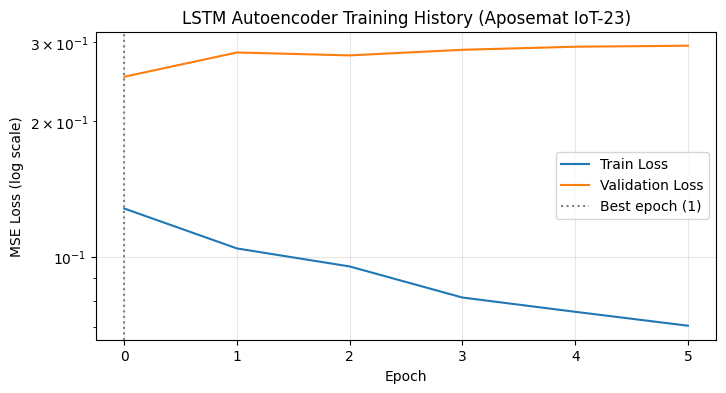

In [ ]:
# If validation loss stops improving, terminate training early to avoid overfitting and save time
early_stop = EarlyStopping(  # early-stopping callback (settings below)
    monitor='val_loss',          # watch validation loss
    patience=5,                  # wait 5 epochs with no improvement before stopping
    restore_best_weights=True    # roll back to the best-performing weights when stopping
)

# During training, store the best model checkpoint to disk (in case Colab disconnects)
checkpoint = ModelCheckpoint(  # checkpoint callback (settings below)
    '/content/best_lstm_autoencoder_iot23.keras',   # save path
    monitor='val_loss',                             # save whenever val_loss improves
    save_best_only=True                             # only keep the best version, not every epoch
)

# Halve the learning rate when validation loss plateaus (helps the model settle into a better minimum)
reduce_lr = ReduceLROnPlateau(  # learning-rate scheduler callback (settings below)
    monitor='val_loss',    # watch validation loss
    factor=0.5,            # multiply the learning rate by 0.5 on a plateau
    patience=2,            # wait 2 epochs without improvement first
    min_lr=1e-5,           # never go below this learning rate
    verbose=1              # print a message whenever the rate changes
)

# Teach the autoencoder to rebuild its own input, which is why X and y are identical here
history = autoencoder.fit(  # start training (settings below)
    X_train_final, X_train_final,                    # input = target = benign sequences (reconstruction task)
    validation_data=(X_val_final, X_val_final),      # validate on held-out benign sequences from unseen blocks
    epochs=50,                                       # maximum number of passes over the data
    batch_size=128,                                  # number of sequences processed per gradient update
    callbacks=[early_stop, checkpoint, reduce_lr],   # attach our callbacks
    verbose=1                                        # print progress per epoch
)

# To visually verify the model learned correctly (no overfitting), plot training vs. validation loss
best_epoch = int(np.argmin(history.history['val_loss']))                          # epoch with the lowest validation loss
plt.figure(figsize=(8, 4))                                                        # set figure size
plt.plot(history.history['loss'], label='Train Loss')                             # training loss curve
plt.plot(history.history['val_loss'], label='Validation Loss')                    # validation loss curve
plt.axvline(best_epoch, color='gray', linestyle=':', label=f'Best epoch ({best_epoch + 1})')   # mark the best epoch
plt.yscale('log')                                                                 # log scale makes late-epoch differences visible
plt.xlabel('Epoch')                                                               # x-axis label
plt.ylabel('MSE Loss (log scale)')                                                # y-axis label
plt.title('LSTM Autoencoder Training History (Aposemat IoT-23)')                  # chart title
plt.legend()                                                                      # show the legend
plt.grid(alpha=0.3)                                                               # light grid for readability
plt.show()

**10. Reconstructin Error, Benign-Distribution, and Anomaly Threshold**

Anomaly threshold (from 95th percentile of benign val error): 0.038531

Benign reconstruction-error comparison (median / 95th percentile):
  Train (seen):        0.000312 / 0.035788
  Validation (unseen): 0.000312 / 0.038531
  Test benign:         0.000312 / 27.702225

KS statistic (val vs test benign): 0.1685  (0 = identical distributions, 1 = completely different)
Benign false-positive rate on TEST: 20.70%  (threshold was designed for ~5.0%)


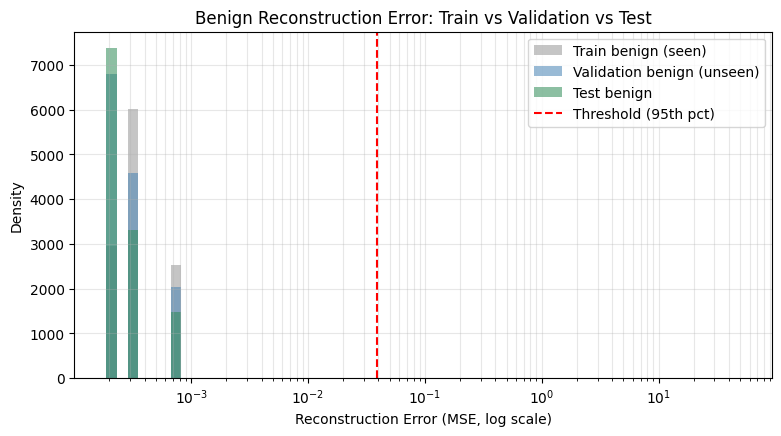

In [ ]:
# Reconstruction Error is how far the LSTM model's output deviates from its input
# Mean Squared Error per sequence (averaged across timesteps and features) quantifies this.



def compute_reconstruction_error(model, data, batch_size=4096):  # helper that scores sequences in batches
    """
    Runs the model on `data` in batches and returns one MSE value per sequence
    (how badly the model reconstructed each individual window). Batching keeps RAM usage low.
    """
    errors = np.empty(len(data), dtype=np.float32)                                       # output array, one error per sequence
    for start in range(0, len(data), batch_size):                                        # walk through the data in batches
        batch = data[start:start + batch_size]                                           # current batch of sequences
        recon = model.predict(batch, batch_size=batch_size, verbose=0)                   # the model's reconstruction of this batch
        errors[start:start + len(batch)] = np.mean(np.square(batch - recon), axis=(1, 2))   # MSE across timesteps + features
    return errors                                                                        # one anomaly score per sequence

# Reference "normal" distribution = BENIGN VALIDATION errors (from blocks the model never trained on)
val_errors = compute_reconstruction_error(autoencoder, X_val_final)  # errors on benign validation sequences

# Use a high percentile of benign validation errors as the anomaly threshold; anything above it is flagged
# At the 95th percentile we accept ~5% of benign traffic being flagged (false positives); adjust to your tolerance
THRESHOLD_PERCENTILE = 95                                                                # same percentile as the CICIoT2023 notebook
threshold = np.percentile(val_errors, THRESHOLD_PERCENTILE)                              # the decision boundary
print(f"Anomaly threshold (from {THRESHOLD_PERCENTILE}th percentile of benign val error): {threshold:.6f}")  # print the message/results

# Score every TEST sequence now (reused by all later cells)
test_errors = compute_reconstruction_error(autoencoder, X_test_seq)                      # anomaly score for each test sequence

# ---------- Benign distribution-shift diagnostic ----------
# If benign TEST traffic looks very different from benign VALIDATION traffic, the threshold will over/under-flag.
# This check quantifies that risk directly (it was the main weakness observed on CICIoT2023).
train_sample = X_train_final[np.random.default_rng(SEED).choice(len(X_train_final), size=min(50_000, len(X_train_final)), replace=False)]   # random training subset
train_errors = compute_reconstruction_error(autoencoder, train_sample)                   # errors on data the model was trained on
benign_test_mask = test_seq_labels == 'Benign'                                           # test sequences that are benign
test_benign_errors = test_errors[benign_test_mask]                                       # their reconstruction errors

if len(test_benign_errors) > 0:                                                          # only if the test set contains benign traffic
    ks_stat, ks_p = ks_2samp(val_errors, test_benign_errors)                             # are val-benign and test-benign errors from the same distribution?
    benign_fpr_test = float((test_benign_errors > threshold).mean())                     # share of benign test traffic wrongly flagged
    expected_fpr = (100 - THRESHOLD_PERCENTILE) / 100                                    # what the threshold was designed to allow
    print("\nBenign reconstruction-error comparison (median / 95th percentile):")         # heading
    print(f"  Train (seen):        {np.median(train_errors):.6f} / {np.percentile(train_errors, 95):.6f}")            # training data
    print(f"  Validation (unseen): {np.median(val_errors):.6f} / {np.percentile(val_errors, 95):.6f}")                # validation data
    print(f"  Test benign:         {np.median(test_benign_errors):.6f} / {np.percentile(test_benign_errors, 95):.6f}")   # test benign data
    print(f"\nKS statistic (val vs test benign): {ks_stat:.4f}  (0 = identical distributions, 1 = completely different)")   # distance between distributions
    print(f"Benign false-positive rate on TEST: {benign_fpr_test * 100:.2f}%  (threshold was designed for ~{expected_fpr * 100:.1f}%)")   # design vs reality
    if benign_fpr_test > 2 * expected_fpr:                                               # flag a large gap
        print("WARNING: benign test traffic is noticeably harder than validation traffic (distribution shift) — report this as a limitation.")  # print the message/results
    else:  # otherwise
        print("Benign test traffic behaves similarly to validation traffic — the threshold generalises well.")  # print the message/results

    plt.figure(figsize=(9, 4.5))                                                         # figure for the overlay
    all_e = np.concatenate([train_errors, val_errors, test_benign_errors])               # pool all errors to share bin edges
    bins = np.logspace(np.log10(max(all_e.min(), 1e-8)), np.log10(all_e.max() + 1e-8), 60)   # log-spaced bins
    plt.hist(train_errors + 1e-12, bins=bins, alpha=0.45, density=True, label='Train benign (seen)', color='gray')            # training distribution
    plt.hist(val_errors + 1e-12, bins=bins, alpha=0.55, density=True, label='Validation benign (unseen)', color='steelblue')  # validation distribution
    plt.hist(test_benign_errors + 1e-12, bins=bins, alpha=0.55, density=True, label='Test benign', color='seagreen')          # test benign distribution
    plt.axvline(threshold, color='red', linestyle='--', label=f'Threshold ({THRESHOLD_PERCENTILE}th pct)')                   # decision boundary
    plt.xscale('log')                                                                    # log x-axis handles the heavy right tail
    plt.xlabel('Reconstruction Error (MSE, log scale)')                                  # x-axis label
    plt.ylabel('Density')                                                                # y-axis label
    plt.title('Benign Reconstruction Error: Train vs Validation vs Test')                # chart title
    plt.legend()                                                                         # show the legend
    plt.grid(alpha=0.3, which='both')                                                    # light grid
    plt.show()                                                                           # render the plot
else:  # otherwise
    print("No benign sequences in the test set — skipping the distribution-shift diagnostic.")   # nothing to compare

**11. Evaluating on the Full Test Set - Benign and All Attack Types**

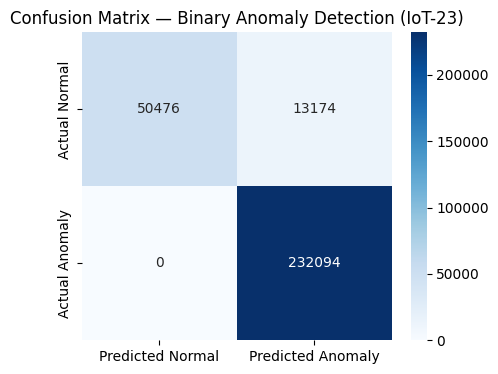

Classification Report (Normal vs Anomaly):
              precision    recall  f1-score   support

      Normal       1.00      0.79      0.88     63650
     Anomaly       0.95      1.00      0.97    232094

    accuracy                           0.96    295744
   macro avg       0.97      0.90      0.93    295744
weighted avg       0.96      0.96      0.95    295744

ROC-AUC Score:                0.8104   (0.5 = random)
PR-AUC (Average Precision):   0.8906   (random baseline = 0.7848, the anomaly share)
Matthews Correlation Coeff.:  0.8663
Balanced Accuracy:            0.8965
False-Positive Rate:          20.70%
True-Positive Rate (Recall):  100.00%


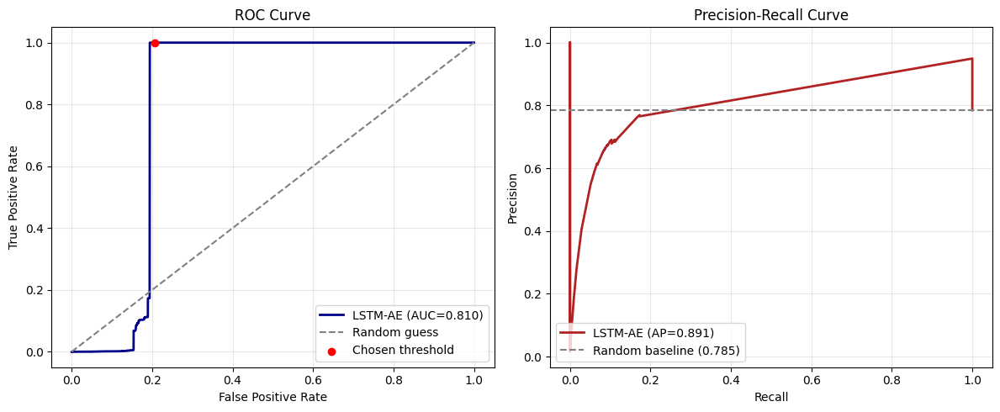

In [ ]:
# Classify each sequence as anomalous (1) if its error exceeds the threshold, normal (0) otherwise
y_pred = (test_errors > threshold).astype(int)            # model's predicted anomaly flag

# Build the TRUE labels: 0 = Benign, 1 = Anomaly (any of DoS/DDoS/BruteForce/Botnet)
y_true = (test_seq_labels != 'Benign').astype(int)        # ground-truth anomaly flag
assert y_true.min() != y_true.max(), "The test set contains only one class — cannot compute ROC/PR metrics."   # both classes are required

# The Confusion Matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])      # rows = actual, cols = predicted
tn, fp, fn, tp = cm.ravel()                               # unpack the four cells

plt.figure(figsize=(5, 4))                                # figure size
sns.heatmap(  # draw the heatmap (settings below)
    cm, annot=True, fmt='d', cmap='Blues',                                        # show counts as integers
    xticklabels=['Predicted Normal', 'Predicted Anomaly'],                        # column names
    yticklabels=['Actual Normal', 'Actual Anomaly']                               # row names
)
plt.title('Confusion Matrix — Binary Anomaly Detection (IoT-23)')                 # chart title
plt.show()                                                                        # render the plot

# The Precision / Recall / F1 Report
print("Classification Report (Normal vs Anomaly):")                               # heading
print(classification_report(y_true, y_pred, target_names=['Normal', 'Anomaly'], zero_division=0))   # per-class metrics

# Threshold-independent scores use the raw reconstruction error (continuous), so they show how well normal and anomalous
# scores separate regardless of the threshold we selected
auc = roc_auc_score(y_true, test_errors)                                          # area under the ROC curve
ap_score = average_precision_score(y_true, test_errors)                           # area under the precision-recall curve
prevalence = y_true.mean()                                                        # share of anomalies in the test set (PR-AUC baseline)

# Threshold-dependent scores at our chosen 95th-percentile threshold
mcc = matthews_corrcoef(y_true, y_pred)                                           # balanced single-number quality score (-1..1)
bal_acc = balanced_accuracy_score(y_true, y_pred)                                 # average of normal-recall and anomaly-recall
fpr_value = fp / (fp + tn) if (fp + tn) > 0 else float('nan')                     # false-positive rate on benign traffic
tpr_value = tp / (tp + fn) if (tp + fn) > 0 else float('nan')                     # true-positive rate (recall) on attacks

print(f"ROC-AUC Score:                {auc:.4f}   (0.5 = random)")                # separability of the scores
print(f"PR-AUC (Average Precision):   {ap_score:.4f}   (random baseline = {prevalence:.4f}, the anomaly share)")   # precision-recall quality
print(f"Matthews Correlation Coeff.:  {mcc:.4f}")                                 # robust to class imbalance
print(f"Balanced Accuracy:            {bal_acc:.4f}")                             # fair under imbalance
print(f"False-Positive Rate:          {fpr_value * 100:.2f}%")                    # benign wrongly flagged
print(f"True-Positive Rate (Recall):  {tpr_value * 100:.2f}%")                    # attacks caught

# Plot ROC and Precision-Recall curves side by side
fpr_arr, tpr_arr, _ = roc_curve(y_true, test_errors)                              # ROC curve points
prec_arr, rec_arr, _ = precision_recall_curve(y_true, test_errors)                # PR curve points
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(12, 5))                        # two panels
ax_roc.plot(fpr_arr, tpr_arr, color='darkblue', linewidth=2, label=f'LSTM-AE (AUC={auc:.3f})')   # ROC curve
ax_roc.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random guess')   # random baseline
ax_roc.scatter([fpr_value], [tpr_value], color='red', zorder=5, label='Chosen threshold')   # operating point
ax_roc.set_xlabel('False Positive Rate')                                          # x label
ax_roc.set_ylabel('True Positive Rate')                                           # y label
ax_roc.set_title('ROC Curve')                                                     # panel title
ax_roc.legend(loc='lower right')                                                  # legend
ax_roc.grid(alpha=0.3)                                                            # grid
ax_pr.plot(rec_arr, prec_arr, color='firebrick', linewidth=2, label=f'LSTM-AE (AP={ap_score:.3f})')   # PR curve
ax_pr.axhline(prevalence, color='gray', linestyle='--', label=f'Random baseline ({prevalence:.3f})')  # random baseline
ax_pr.set_xlabel('Recall')                                                        # x label
ax_pr.set_ylabel('Precision')                                                     # y label
ax_pr.set_title('Precision-Recall Curve')                                         # panel title
ax_pr.legend(loc='lower left')                                                    # legend
ax_pr.grid(alpha=0.3)                                                             # grid
plt.tight_layout()                                                                # avoid overlapping labels
plt.show()

**12. Per-Attack-Type Detection Breakdown**

Benign       | n=  63650 | correct rate:  79.30%
DDoS         | n=  15031 | correct rate: 100.00%
BruteForce   | n=    102 | correct rate: 100.00%
Botnet       | n= 216961 | correct rate: 100.00%


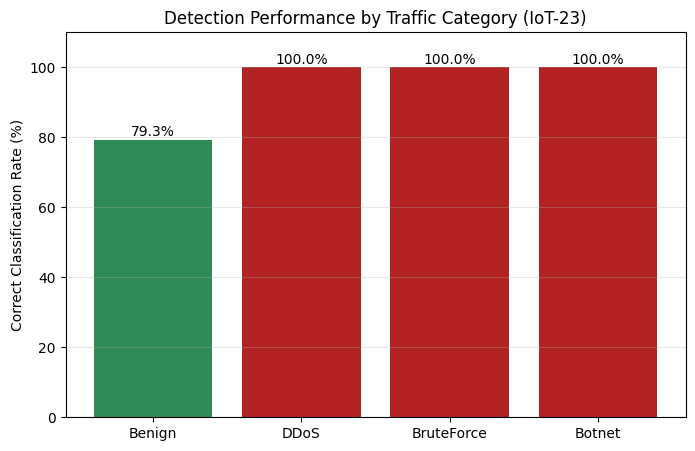


Per-behaviour breakdown (test set):
  detailed_label   category      n          metric   rate
           Okiru     Botnet 212128    detected (%) 100.00
          Benign     Benign  63650 kept normal (%)  79.30
            DDoS       DDoS  15031    detected (%) 100.00
             C&C     Botnet   4567    detected (%) 100.00
   C&C-HeartBeat     Botnet    227    detected (%) 100.00
          Attack BruteForce    102    detected (%) 100.00
       C&C-Torii     Botnet     30    detected (%) 100.00
C&C-FileDownload     Botnet      8    detected (%) 100.00
       C&C-Mirai     Botnet      1    detected (%) 100.00


In [ ]:
# One "Normal vs Anomaly" figure conceals a lot; here we test the ability to identify
# EVERY distinct category (DoS, DDoS, BruteForce and Botnet separately) and every detailed IoT-23 behaviour

categories_to_check = ['Benign', 'DoS', 'DDoS', 'BruteForce', 'Botnet']   # our 5 target classes (DoS is absent from IoT-23)
detection_rates = {}                                                       # will store {category: percentage_correctly_classified}

for cat in categories_to_check:                                            # loop over each category
    mask = test_seq_labels == cat                                          # sequences belonging to this category
    if mask.sum() == 0:                                                    # skip if this category doesn't appear in the test set
        continue  # skip to the next item
    cat_pred = (test_errors[mask] > threshold).astype(int)                 # predicted anomaly flags for this category
    if cat == 'Benign':  # benign is scored differently from attacks
        correct_rate = (cat_pred == 0).mean() * 100                        # for benign, "correct" means predicted NORMAL
    else:  # otherwise
        correct_rate = (cat_pred == 1).mean() * 100                        # for attacks, "correct" means predicted ANOMALY (recall)
    detection_rates[cat] = correct_rate                                    # store the result
    small_flag = '  <-- small sample, interpret with care' if mask.sum() < 100 else ''   # warn about tiny categories
    print(f"{cat:12s} | n={mask.sum():7d} | correct rate: {correct_rate:6.2f}%{small_flag}")   # one line per category

# Bar chart visualizing detection rate per category
plt.figure(figsize=(8, 5))                                                 # figure size
bars = plt.bar(detection_rates.keys(), detection_rates.values(),  # draw one bar per category (colours below)
               color=['seagreen' if k == 'Benign' else 'firebrick' for k in detection_rates.keys()])   # green = benign, red = attacks
plt.ylabel('Correct Classification Rate (%)')                              # y label
plt.title('Detection Performance by Traffic Category (IoT-23)')            # title
plt.ylim(0, 110)                                                           # headroom for the labels
plt.grid(axis='y', alpha=0.3)                                              # light grid
for bar, value in zip(bars, detection_rates.values()):                     # label each bar with its exact percentage
    plt.text(bar.get_x() + bar.get_width() / 2, value + 1, f'{value:.1f}%', ha='center')  # write the value above the bar
plt.show()                                                                 # render the plot

# ---- Finer view: every detailed IoT-23 behaviour present in the test set ----
detail_rows = []                                                           # accumulates one row per detailed label
for det in pd.Series(test_seq_detail).value_counts().index:                # most frequent behaviours first
    m = test_seq_detail == det                                             # sequences ending in this behaviour
    is_benign_det = det == 'Benign'                                        # benign is scored differently
    flagged = (test_errors[m] > threshold).mean() * 100                    # % of these sequences flagged as anomalous
    detail_rows.append({'detailed_label': det, 'category': test_seq_labels[m][0], 'n': int(m.sum()),  # store this behaviour's statistics (continues below)
                        'metric': 'kept normal (%)' if is_benign_det else 'detected (%)',  # which metric applies to this row
                        'rate': (100 - flagged) if is_benign_det else flagged})   # correct rate for this behaviour
detail_df = pd.DataFrame(detail_rows)                                      # tabulate
print("\nPer-behaviour breakdown (test set):")                              # heading
print(detail_df.head(20).to_string(index=False, float_format=lambda v: f'{v:.2f}'))   # show up to the 20 most common behaviours

**13. Reconstruction Distribution Errors by Attack Type**

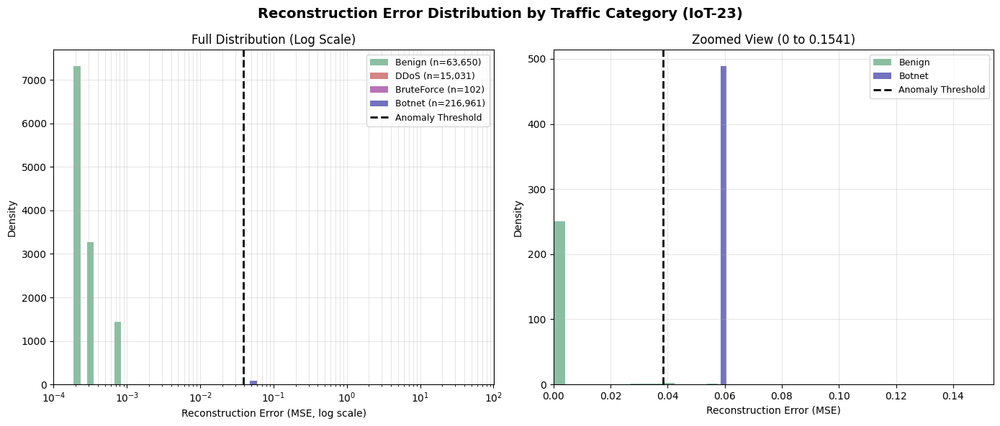

In [ ]:
# Overlay the error distribution for each category. This displays which attack types the model struggles with, because it shows how well-separated each specific type is from regular traffic.

fig, (ax_main, ax_zoom) = plt.subplots(1, 2, figsize=(14, 6))      # two side-by-side panels

colors = {'Benign': 'seagreen', 'DoS': 'orange', 'DDoS': 'firebrick',  # colour lookup (continues below)
          'BruteForce': 'purple', 'Botnet': 'darkblue'}            # distinct colour per category

EPS = 1e-6                                                         # small epsilon added before log to avoid log(0) errors

# ---- LEFT PANEL: full distribution, log-scaled x-axis ----
all_pos = test_errors[test_errors > 0]                             # positive errors only (needed for log bins)
log_bins = np.logspace(np.log10(max(all_pos.min(), EPS)), np.log10(all_pos.max() + EPS), 60)   # shared log-spaced bins
for cat in categories_to_check:                                    # loop over categories
    mask = test_seq_labels == cat                                  # boolean mask for this category
    if mask.sum() == 0:                                            # skip categories with no samples in the test set
        continue  # skip to the next item
    ax_main.hist(test_errors[mask] + EPS, bins=log_bins, alpha=0.55, label=f'{cat} (n={mask.sum():,})',  # histogram for this category (colour below)
                 color=colors.get(cat, 'gray'), density=True)      # normalised histogram for this category

ax_main.axvline(threshold, color='black', linestyle='--', linewidth=2, label='Anomaly Threshold')   # decision boundary
ax_main.set_xscale('log')                                          # log scale spreads out the crammed low-value detail
ax_main.set_xlabel('Reconstruction Error (MSE, log scale)')        # x label
ax_main.set_ylabel('Density')                                      # y label
ax_main.set_title('Full Distribution (Log Scale)')                 # panel title
ax_main.legend(fontsize=9)                                         # legend
ax_main.grid(alpha=0.3, which='both')                              # grid

# ---- RIGHT PANEL: zoomed in on the threshold region (linear scale) ----
zoom_upper = threshold * 4                                         # show up to 4x the threshold value — adjust if needed
for cat in categories_to_check:                                    # loop over categories again
    mask = test_seq_labels == cat                                  # boolean mask for this category
    if mask.sum() == 0:                                            # skip empty categories
        continue  # skip to the next item
    zoomed_errors = test_errors[mask]                              # errors for this category
    zoomed_errors = zoomed_errors[zoomed_errors <= zoom_upper]     # keep only errors inside the zoom window
    if len(zoomed_errors) == 0:                                    # nothing to draw
        continue  # skip to the next item
    ax_zoom.hist(zoomed_errors, bins=40, alpha=0.55, label=cat, color=colors.get(cat, 'gray'), density=True)   # zoomed histogram

ax_zoom.axvline(threshold, color='black', linestyle='--', linewidth=2, label='Anomaly Threshold')   # decision boundary
ax_zoom.set_xlim(0, zoom_upper)                                    # restrict the x-range to the zoom window
ax_zoom.set_xlabel('Reconstruction Error (MSE)')                   # x label
ax_zoom.set_ylabel('Density')                                      # y label
ax_zoom.set_title(f'Zoomed View (0 to {zoom_upper:.4f})')          # panel title
ax_zoom.legend(fontsize=9)                                         # legend
ax_zoom.grid(alpha=0.3)                                            # grid

plt.suptitle('Reconstruction Error Distribution by Traffic Category (IoT-23)', fontsize=14, fontweight='bold')   # overall title
plt.tight_layout()                                                 # avoid overlapping labels
plt.show()                                                         # render the figure

**14. Two-Panel Detection Demo Live Stream**

In [ ]:
# A two-panel replay: the top panel streams reconstruction error against the threshold, the bottom panel keeps running counts.
# NOTE: This section is a dataset REPLAY simulation, not a live packet capture (which is outside of the scope)

N_DEMO_STEPS = 300                                                 # how many sequences to replay (keep small for a smooth animation)
is_attack_seq = (test_seq_labels != 'Benign').astype(int)          # 1 = attack, 0 = benign for each test sequence
if len(is_attack_seq) > N_DEMO_STEPS:                              # pick an informative replay segment
    cs = np.concatenate(([0], np.cumsum(is_attack_seq)))           # running count of attack sequences
    seg_share = (cs[N_DEMO_STEPS:] - cs[:-N_DEMO_STEPS]) / N_DEMO_STEPS   # attack share inside every possible segment
    demo_start = int(np.argmin(np.abs(seg_share - 0.35)))          # segment closest to ~35% attacks, so both classes are visible
else:  # otherwise
    N_DEMO_STEPS, demo_start = len(is_attack_seq), 0               # tiny test set: replay everything

demo_errors = test_errors[demo_start:demo_start + N_DEMO_STEPS]            # reconstruction errors for the demo window
demo_labels = test_seq_labels[demo_start:demo_start + N_DEMO_STEPS]        # matching ground-truth labels for reference
demo_plot = np.maximum(demo_errors, 1e-8)                                  # avoid zeros on the log-scaled axis
demo_flags = demo_errors > threshold                                       # which replayed sequences are flagged as anomalies
print(f"Demo window: sequences {demo_start}-{demo_start + N_DEMO_STEPS - 1} | attacks in window: {(demo_labels != 'Benign').sum()}")   # describe the segment

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7))                      # two stacked panels

# Panel 1: The Rolling Error Stream
line, = ax1.plot([], [], color='steelblue', lw=1.5, label='Reconstruction Error')      # error line (empty initially)
flag_points = ax1.scatter([], [], color='red', s=22, zorder=3, label='Flagged anomaly')   # red dots for flagged sequences
ax1.axhline(threshold, color='red', linestyle='--', label='Threshold')                 # fixed threshold line
ax1.set_xlim(0, N_DEMO_STEPS)                                                          # x-axis spans the whole demo
ax1.set_yscale('log')                                                                  # log axis copes with the heavy-tailed errors
ax1.set_ylim(max(demo_plot.min() * 0.5, 1e-8), demo_plot.max() * 2)                    # y-axis padded around the data
ax1.set_ylabel('Reconstruction Error (log)')                                           # y label
ax1.set_title('Live Anomaly Score Stream (Test Set Replay)')                           # panel title
ax1.legend(loc='upper right')                                                          # legend

# Panel 2: Running Anomaly/Normal Counts
bar_counts = ax2.bar(['Normal', 'Anomaly'], [0, 0], color=['seagreen', 'firebrick'])   # initial empty bars
ax2.set_ylim(0, N_DEMO_STEPS)                                                          # bars can grow up to the full demo length
ax2.set_title('Running Detection Count')                                               # panel title

def init():  # animation start-up function
    """Initializes the animation with empty data."""
    line.set_data([], [])                                          # clear the error line
    flag_points.set_offsets(np.empty((0, 2)))                      # clear the flagged points
    return (line, flag_points, *bar_counts)                        # artists that will be redrawn

def update(frame):  # animation per-frame function
    """Called once per animation frame — adds one more data point to the stream."""
    line.set_data(np.arange(frame + 1), demo_plot[:frame + 1])     # error values up to the current frame
    flagged_idx = np.flatnonzero(demo_flags[:frame + 1])           # positions flagged so far
    flag_points.set_offsets(np.column_stack([flagged_idx, demo_plot[flagged_idx]]))   # draw red dots on flagged points
    n_anomaly = int(demo_flags[:frame + 1].sum())                  # anomalies flagged so far
    n_normal = frame + 1 - n_anomaly                               # normals so far
    bar_counts[0].set_height(n_normal)                             # update normal bar height
    bar_counts[1].set_height(n_anomaly)                            # update anomaly bar height
    return (line, flag_points, *bar_counts)                        # artists that changed

# Create the animation: one frame per demo sequence, 50ms between frames
anim = animation.FuncAnimation(fig, update, frames=N_DEMO_STEPS, init_func=init, interval=50, blit=False, repeat=False)  # build the animation: one frame per sequence, 50 ms apart
plt.tight_layout()                                                 # avoid overlapping labels
plt.close(fig)                                                     # prevent a duplicate static figure from displaying
HTML(anim.to_jshtml())                                             # render the animation inline in the Colab output cell

Demo window: sequences 99850-100149 | attacks in window: 105


**15. Reconstructin Error, Benign-Distribution, and Anomaly Threshold**

In [ ]:
# The model uses ONE fixed threshold which is the 95th percentile of benign validation error.
# This cell tests a whole range of thresholds and displays precision/recall/F1/false-positive-rate at each one, turning "we picked 95%" into "we tested this and here is the evidence for our choice".
# NOTE: this sweep is an ANALYSIS on the test set — the deployed threshold stays the validation-based 95th percentile.

percentiles_to_test = np.arange(80, 99.5, 0.5)         # sweep from 80th to 99th percentile in 0.5 steps
sweep_results = []                                     # will store one dictionary per percentile

for pct in percentiles_to_test:                        # loop over candidate thresholds
    test_threshold = np.percentile(val_errors, pct)    # candidate threshold at this percentile of benign validation error
    preds = (test_errors > test_threshold).astype(int) # predictions at this threshold
    sweep_results.append({  # store the metrics for this percentile
        'percentile': pct,                                                        # percentile used
        'threshold': test_threshold,                                              # the actual error value
        'precision': precision_score(y_true, preds, zero_division=0),             # precision at this threshold
        'recall': recall_score(y_true, preds, zero_division=0),                   # recall at this threshold
        'f1': f1_score(y_true, preds, zero_division=0),                           # F1 at this threshold
        'fpr': float(preds[y_true == 0].mean())                                   # benign traffic wrongly flagged
    })

sweep_df = pd.DataFrame(sweep_results)                 # convert to a DataFrame for easy plotting/inspection

# Find the percentile that MAXIMIZES F1 — the "best" trade-off point on this test set
best_row = sweep_df.loc[sweep_df['f1'].idxmax()]       # row with the highest F1
print(f"Best F1 achieved at {best_row['percentile']:.1f}th percentile "  # print the message/results
      f"(threshold={best_row['threshold']:.6f}) — Precision: {best_row['precision']:.3f}, "  # print the message/results
      f"Recall: {best_row['recall']:.3f}, F1: {best_row['f1']:.3f}, FPR: {best_row['fpr']:.3f}")  # print the message/results
print("\nFor comparison, our CHOSEN threshold (95th percentile) gives:")   # heading
print(sweep_df[np.isclose(sweep_df['percentile'], 95.0)].to_string(index=False))   # the row for the chosen percentile

# Plot precision, recall, F1 and false-positive rate as the threshold percentile changes
plt.figure(figsize=(10, 6))                                                                          # figure size
plt.plot(sweep_df['percentile'], sweep_df['precision'], label='Precision', color='steelblue', marker='o', markersize=3)    # precision curve
plt.plot(sweep_df['percentile'], sweep_df['recall'], label='Recall', color='firebrick', marker='o', markersize=3)          # recall curve
plt.plot(sweep_df['percentile'], sweep_df['f1'], label='F1-Score', color='seagreen', marker='o', markersize=3)             # F1 curve
plt.plot(sweep_df['percentile'], sweep_df['fpr'], label='False-Positive Rate', color='darkorange', linestyle='--')         # FPR curve
plt.axvline(95, color='black', linestyle='--', alpha=0.7, label='Chosen Threshold (95th pct)')                              # chosen threshold
plt.axvline(best_row['percentile'], color='purple', linestyle=':', alpha=0.7, label=f"Best F1 ({best_row['percentile']:.1f}th pct)")   # best-F1 threshold
plt.xlabel('Threshold Percentile')                                                                   # x label
plt.ylabel('Score')                                                                                  # y label
plt.title('Threshold Sensitivity: Precision / Recall / F1 / FPR vs. Decision Boundary')              # title
plt.legend()                                                                                         # legend
plt.grid(alpha=0.3)                                                                                  # grid
plt.show()

**16. Feature-Level Explainability = The Features that Drive Anomaly Detection**

In [ ]:
# We may declare, for example, that "the model catches DDoS mainly because it cannot reconstruct packet-rate and connection-state features" because this cell breaks down the reconstruction error per feasture
#  The brief's need to "interpret the anomaly in network behavior" is explicitly addressed by this.


def compute_per_feature_error(model, data, batch_size=4096):  # helper for per-feature error
    """
    Returns the average reconstruction error contributed by EACH individual feature (one value per feature),
    instead of one combined score per sequence. Batched so it stays memory-friendly.
    """
    sums = np.zeros(data.shape[2], dtype=np.float64)                                  # running sum of squared error per feature
    for start in range(0, len(data), batch_size):                                     # walk through the data in batches
        batch = data[start:start + batch_size]                                        # current batch
        recon = model.predict(batch, batch_size=batch_size, verbose=0)                # reconstruction of this batch
        sums += np.sum(np.square(batch - recon), axis=(0, 1))                         # add squared error per feature
    return sums / (len(data) * data.shape[1])                                         # mean over sequences and timesteps

feature_error_by_category = {}                                                        # will store {category: per-feature error array}
explain_rng = np.random.default_rng(SEED)                                             # reproducible sampling

for cat in categories_to_check:                                                       # loop over categories
    idx = np.flatnonzero(test_seq_labels == cat)                                      # positions of this category's sequences
    if len(idx) == 0:                                                                 # skip absent categories
        continue  # skip to the next item
    if len(idx) > 20_000:                                                             # cap for speed
        idx = np.sort(explain_rng.choice(idx, size=20_000, replace=False))            # random subset
    feature_error_by_category[cat] = pd.Series(compute_per_feature_error(autoencoder, X_test_seq[idx]), index=feature_cols)   # per-feature error

assert 'Benign' in feature_error_by_category, "Need benign test sequences to build the comparison."   # benign is the reference
benign_feat_err = feature_error_by_category['Benign']                                 # per-feature benign error

comparison = pd.DataFrame({'benign_error': benign_feat_err})                          # start the comparison table
for cat, series in feature_error_by_category.items():                                  # add one gap column per attack category
    if cat != 'Benign':  # only attack categories get a gap column
        comparison[f'{cat}_gap'] = series - benign_feat_err                           # how much WORSE than benign this feature reconstructs
gap_cols = [c for c in comparison.columns if c.endswith('_gap')]                      # names of the gap columns
comparison['avg_gap'] = comparison[gap_cols].mean(axis=1)                             # average gap across attack types
top_features = comparison.sort_values('avg_gap', ascending=False).head(10)            # the 10 most discriminative features

print("Top 10 most discriminative features (largest error gap between benign and attack traffic):")   # heading
print(top_features[['benign_error'] + gap_cols + ['avg_gap']].round(4).to_string())   # show the table

# Horizontal bar chart of the top discriminative features
plt.figure(figsize=(9, 6))                                                            # figure size
plt.barh(top_features.index[::-1], top_features['avg_gap'][::-1], color='darkorange') # largest gap at the top
plt.xlabel('Average Reconstruction Error Gap (Attack − Benign)')                      # x label
plt.title('Top 10 Most Discriminative Features for Anomaly Detection (IoT-23)')       # title
plt.grid(axis='x', alpha=0.3)                                                         # grid
plt.tight_layout()                                                                    # avoid clipped labels
plt.show()                                                                            # render the plot

# Heatmap: which features matter for WHICH attack type
if len(gap_cols) > 0:                                                                 # only if at least one attack category exists
    plt.figure(figsize=(1.6 * len(gap_cols) + 4, 6))                                  # width scales with the number of categories
    sns.heatmap(top_features[gap_cols].rename(columns=lambda c: c.replace('_gap', '')), annot=True, fmt='.2f',  # draw the heatmap
                cmap='YlOrRd', robust=True)                                           # error gap per feature per attack type
    plt.title('Error Gap by Feature and Attack Type (top 10 features)')               # title
    plt.ylabel('Feature')                                                             # y label
    plt.tight_layout()                                                                # avoid clipped labels
    plt.show()

**17. Per-Attack-Type ROC Curves (One vs Benign)**

In [ ]:
# The single ROC-AUC in Cell 11 lumps all attack types together against benign. That hides the fact that some behaviours (e.g. botnet command-and-control) can be far more detectable than others.
# This cell draws a SEPARATE ROC curve per attack type.

plt.figure(figsize=(8, 7))                                                   # figure size

attack_categories = ['DoS', 'DDoS', 'BruteForce', 'Botnet']                  # exclude Benign itself — it's the reference class
colors_roc = {'DoS': 'orange', 'DDoS': 'firebrick', 'BruteForce': 'purple', 'Botnet': 'darkblue'}   # colour per attack type
per_attack_auc, per_attack_ap = {}, {}                                       # store ROC-AUC and PR-AUC per attack type

for attack in attack_categories:                                             # loop over attack categories
    n_attack = (test_seq_labels == attack).sum()                             # how many test sequences of this attack exist
    if n_attack == 0:                                                        # skip if this attack type has no test samples
        continue  # skip to the next item
    mask = (test_seq_labels == attack) | (test_seq_labels == 'Benign')       # ONE-VS-BENIGN subset: this attack + all benign
    subset_errors = test_errors[mask]                                        # reconstruction errors for this subset
    subset_true = (test_seq_labels[mask] == attack).astype(int)              # 1 = this attack, 0 = benign

    fpr_a, tpr_a, _ = roc_curve(subset_true, subset_errors)                  # ROC curve points
    per_attack_auc[attack] = roc_auc_score(subset_true, subset_errors)       # AUC for this specific attack type
    per_attack_ap[attack] = average_precision_score(subset_true, subset_errors)   # PR-AUC for this attack type
    plt.plot(fpr_a, tpr_a, label=f'{attack} (AUC={per_attack_auc[attack]:.3f}, n={n_attack:,})',  # draw the curve
             color=colors_roc.get(attack, 'gray'), linewidth=2)              # draw the curve

plt.plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=1, label='Random Guess (AUC=0.5)')   # random-guessing baseline
plt.xlabel('False Positive Rate')                                            # x label
plt.ylabel('True Positive Rate')                                             # y label
plt.title('ROC Curves by Attack Type (vs. Benign Traffic) — IoT-23')         # title
plt.legend(loc='lower right')                                                # legend
plt.grid(alpha=0.3)                                                          # grid
plt.show()                                                                   # render the plot

# Summary table ranking attack types by how well-separated they are from benign
auc_summary = pd.DataFrame({'ROC-AUC': pd.Series(per_attack_auc), 'PR-AUC': pd.Series(per_attack_ap)}).sort_values('ROC-AUC', ascending=False)   # ranked table
print("Attack types ranked by separability from benign traffic:")            # heading
print(auc_summary.round(4))                                                  # print the table

**18. LSTM Model Efficiency Profile (IoT Deployment Feasibility)**

In [ ]:
# The proposal commits to evaluating "real-world applicability" on resource-constrained IoT hardware.
# This cell checks whether the LSTM model is light enough by profiling model size and inference speed.

# Model size on disk
temp_path = '/content/temp_size_check_iot23.keras'                                  # temporary file used only for measuring
autoencoder.save(temp_path)                                                         # save a copy to measure its file size
model_size_mb = os.path.getsize(temp_path) / (1024 ** 2)                            # convert bytes to MB
os.remove(temp_path)                                                                # clean up the temp file

# Parameter count
total_params = autoencoder.count_params()                                           # total trainable + non-trainable parameters

# Inference latency: how long does ONE sequence take to score?
sample_batch = X_test_seq[:1]                                                       # a single sequence, shape (1, WINDOW_SIZE, N_FEATURES)
_ = autoencoder.predict(sample_batch, verbose=0)                                    # warm-up run (first call is slower due to graph tracing)

n_trials = 100                                                                      # number of timed calls
start_time = time.time()                                                            # start the clock
for _ in range(n_trials):                                                           # repeat for a stable average
    _ = autoencoder.predict(sample_batch, verbose=0)                                # score one sequence through Keras predict()
avg_latency_ms = ((time.time() - start_time) / n_trials) * 1000                     # milliseconds per single sequence

# Throughput: how many sequences per second can we score in a batch?
batch_sample = X_test_seq[:min(1000, len(X_test_seq))]                              # a batch of up to 1000 sequences
start_time = time.time()                                                            # start the clock
_ = autoencoder.predict(batch_sample, verbose=0)                                    # score the whole batch
throughput = len(batch_sample) / (time.time() - start_time)                         # sequences scored per second

print("=" * 55)                                                                     # divider
print("MODEL EFFICIENCY PROFILE")                                                   # title
print("=" * 55)                                                                     # divider
print(f"Total parameters:                 {total_params:,}")                        # model size in parameters
print(f"Model size on disk:               {model_size_mb:.2f} MB")                  # model size in MB
print(f"Avg single-sequence latency:      {avg_latency_ms:.2f} ms (Keras predict)") # latency per sequence (same method as CICIoT2023)
print(f"Batch throughput:                 {throughput:.1f} sequences/sec")          # batch speed
print("=" * 55)                                                                     # divider

# Visualize latency vs. a rough real-world reference point (typical IoT gateway budget ~50-100ms)
reference_budget = 100                                                              # ms — commonly cited edge-inference latency budget
plt.figure(figsize=(7, 4))                                                          # figure size
bars = plt.bar(['Our Model', 'Typical Edge Budget'], [avg_latency_ms, reference_budget],  # two bars: our latency vs the reference budget (colours below)
               color=['seagreen' if avg_latency_ms <= reference_budget else 'firebrick', 'gray'])   # green if within budget
plt.ylabel('Latency (ms)')                                                          # y label
plt.title('Inference Latency vs. Typical Edge-Deployment Budget')                   # title
for bar, val in zip(bars, [avg_latency_ms, reference_budget]):                      # label each bar
    plt.text(bar.get_x() + bar.get_width() / 2, val + 1, f'{val:.1f}ms', ha='center')  # write the value above the bar
plt.grid(axis='y', alpha=0.3)                                                       # grid
plt.show()                                                                          # render the plot

**19. Baseline Comparison: LSTM Autoencoder vs Isolation Forest Demonstration**

In [ ]:
# A result is only meaningful in relation to a reference. A common non-seqeuntial anomaly detector is called Isolation Forest
# Since Isolation Forest lacks a sense of sequence, it only observes the LAST flow of each model.
# Both models are trained on the same innocuous training data and rated on the same test sequences. This demonstrates the temporal modeling added by the LSTM.

iso_rng = np.random.default_rng(SEED)                                                          # reproducible sampling
iso_idx = iso_rng.choice(len(X_train_final), size=min(200_000, len(X_train_final)), replace=False)   # benign training subset
X_iso_train = X_train_final[iso_idx, -1, :]                                                    # last flow of each benign training window
X_iso_test  = X_test_seq[:, -1, :]                                                             # last flow of every test window

iso_forest = IsolationForest(n_estimators=100, contamination='auto', random_state=SEED, n_jobs=-1)   # the baseline model
iso_forest.fit(X_iso_train)                                                                    # fit on benign traffic only
iso_scores = -iso_forest.score_samples(X_iso_test)                                              # higher = more anomalous (sign flipped)

iso_auc = roc_auc_score(y_true, iso_scores)                                                    # baseline ROC-AUC
iso_ap  = average_precision_score(y_true, iso_scores)                                           # baseline PR-AUC

comparison_rows = [{'model': 'LSTM Autoencoder', 'ROC-AUC': auc, 'PR-AUC': ap_score},  # LSTM row (Isolation Forest row below)
                   {'model': 'Isolation Forest', 'ROC-AUC': iso_auc, 'PR-AUC': iso_ap}]        # overall comparison rows
print("Overall comparison (all attacks vs. benign):")                                          # heading
print(pd.DataFrame(comparison_rows).round(4).to_string(index=False))                           # print the table

# Per-attack-type ROC-AUC for both models
per_attack_rows = []                                                                           # accumulates one row per attack type
for attack in attack_categories:                                                               # loop over attack categories
    if (test_seq_labels == attack).sum() == 0:                                                 # skip absent categories
        continue  # skip to the next item
    m = (test_seq_labels == attack) | (test_seq_labels == 'Benign')                            # one-vs-benign subset
    t = (test_seq_labels[m] == attack).astype(int)                                             # 1 = this attack
    per_attack_rows.append({'attack': attack,  # store this attack type's AUCs (continues below)
                            'LSTM-AE AUC': roc_auc_score(t, test_errors[m]),                   # LSTM autoencoder AUC
                            'IsoForest AUC': roc_auc_score(t, iso_scores[m])})                 # Isolation Forest AUC
per_attack_cmp = pd.DataFrame(per_attack_rows).set_index('attack')                             # tabulate
print("\nPer-attack-type ROC-AUC:")                                                             # heading
print(per_attack_cmp.round(4))                                                                 # print the table

per_attack_cmp.plot(kind='bar', figsize=(8, 5), color=['darkblue', 'darkorange'])              # grouped bar chart
plt.axhline(0.5, color='gray', linestyle='--', label='Random (0.5)')                           # random baseline
plt.ylabel('ROC-AUC')                                                                          # y label
plt.title('LSTM Autoencoder vs. Isolation Forest by Attack Type')                              # title
plt.ylim(0, 1.05)                                                                              # AUC range
plt.xticks(rotation=0)                                                                         # keep labels horizontal
plt.legend()                                                                                   # legend
plt.grid(axis='y', alpha=0.3)                                                                  # grid
plt.show()                                                                                     # render the plot

**20. Final Results Summary and Export**

In [ ]:
# Collect every headline number in one table (paste straight into the report/pitch) and save the artefacts other team members need.

summary = {  # dictionary of headline results
    'Dataset': 'Aposemat IoT-23',                                            # dataset name
    'Window size': WINDOW_SIZE,                                              # sequence length
    'Features': N_FEATURES,                                                  # number of input features
    'Train sequences (benign)': len(X_train_final),                          # training set size
    'Validation sequences (benign)': len(X_val_final),                       # validation set size
    'Test sequences': len(X_test_seq),                                       # test set size
    'Threshold percentile': THRESHOLD_PERCENTILE,                            # design percentile
    'Threshold (MSE)': float(threshold),                                     # the decision boundary
    'ROC-AUC': float(auc),                                                   # overall ROC-AUC
    'PR-AUC': float(ap_score),                                               # overall PR-AUC
    'MCC': float(mcc),                                                       # Matthews correlation coefficient
    'Balanced accuracy': float(bal_acc),                                     # balanced accuracy
    'Benign kept-normal rate (%)': float(detection_rates.get('Benign', np.nan)),   # 1 - false-positive rate on benign
    'Precision (Anomaly)': float(precision_score(y_true, y_pred, zero_division=0)),# anomaly precision
    'Recall (Anomaly)': float(recall_score(y_true, y_pred, zero_division=0)),      # anomaly recall
    'F1 (Anomaly)': float(f1_score(y_true, y_pred, zero_division=0)),              # anomaly F1
    'Isolation Forest ROC-AUC': float(iso_auc),                              # baseline ROC-AUC
    'Model parameters': int(total_params),                                   # model size (parameters)
    'Model size (MB)': round(float(model_size_mb), 3),                       # model size on disk
    'Latency per sequence (ms)': round(float(avg_latency_ms), 2),            # inference latency
}
for cat, rate in detection_rates.items():                                    # add each per-category rate
    summary[f'Correct rate — {cat} (%)'] = float(rate)                       # detection/kept-normal rate per category
for cat, a in per_attack_auc.items():                                        # add each per-attack ROC-AUC
    summary[f'ROC-AUC — {cat}'] = float(a)                                   # separability per attack type

summary_df = pd.Series(summary, name='value').to_frame()                     # tabulate as a two-column table
print(summary_df.to_string())                                                # print the full summary

# ---- Save artefacts (download these from the Colab Files panel) ----
summary_df.to_csv('/content/theia_iot23_results_summary.csv')                # results table for the report
joblib.dump(scaler, '/content/theia_iot23_scaler.pkl')                       # fitted scaler (needed to score new traffic)
with open('/content/theia_iot23_config.json', 'w') as f:                     # config needed to reproduce/deploy the detector
    json.dump({'threshold': float(threshold), 'threshold_percentile': THRESHOLD_PERCENTILE,  # write the JSON file
               'window_size': WINDOW_SIZE, 'feature_cols': feature_cols, 'scale_clip': SCALE_CLIP}, f, indent=2)   # write the JSON
autoencoder.save('/content/theia_lstm_autoencoder_iot23_final.keras')        # final trained model
print("\nSaved: results summary CSV, scaler, config JSON and final model to /content/.")   # confirmation